
# Лабораторная работа №2. Классификация: Titanic

**Цель:** пройти полный цикл решения задачи бинарной классификации — исследовать данные пассажиров «Титаника», подготовить признаки, построить baseline, обучить и сравнить несколько алгоритмов машинного обучения, проанализировать метрики, важность признаков и ошибки моделей.

**Источник:** [Titanic Dataset — Kaggle](https://www.kaggle.com/datasets/yasserh/titanic-dataset).


In [15]:
import pandas as pd
from pathlib import Path

# Загрузка данных
data_path = Path("lab02/data/Titanic-Dataset.csv")

if not data_path.exists():
    data_path = Path("data/Titanic-Dataset.csv")

df = pd.read_csv(data_path)

from IPython.display import display

print("Размер датасета:", df.shape)

print("\nНазвания столбцов:")
print(df.columns.tolist())

print("\nПервые пять пассажиров:")
display(df.head())

Размер датасета: (891, 12)

Названия столбцов:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Первые пять пассажиров:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Типы данных, пропуски и дубликаты

Проверим типы столбцов, количество отсутствующих значений и наличие повторяющихся записей.

In [16]:
# Типы признаков
print("Типы данных:")
print(df.dtypes.to_string())

# Пропущенные значения
missing = pd.DataFrame({
    "Количество": df.isna().sum(),
    "Процент": df.isna().mean() * 100
})

print("\nПропущенные значения:")
print(missing[missing["Количество"] > 0].round(2).to_string())

# Проверяем дубликаты
print("\nПолные дубликаты:", df.duplicated().sum())

print(
    "Повторяющиеся PassengerId:",
    df["PassengerId"].duplicated().sum()
)

Типы данных:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str

Пропущенные значения:
          Количество  Процент
Age              177    19.87
Cabin            687    77.10
Embarked           2     0.22

Полные дубликаты: 0
Повторяющиеся PassengerId: 0



**Вывод:** в датасете 891 пассажир, полных дубликатов и повторяющихся PassengerId нет. Пропуски обнаружены в Age (19.87%), Cabin (77.10%) и Embarked (0.22%).

Для Age будем использовать медиану, для Embarked — наиболее частое значение. Cabin пока исключим из модели из-за большого количества пропусков.



## 3. Разделение данных

Разделим датасет на обучающую и тестовую выборки в соотношении 80/20. Используем стратификацию по Survived, чтобы сохранить распределение классов, и зафиксируем random_state для воспроизводимости.


In [17]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["Survived"]
)

print("Train:", train_df.shape)
print("Test:", test_df.shape)

print("\nДоля выживших:")
print(f"Train: {train_df['Survived'].mean():.3f}")
print(f"Test:  {test_df['Survived'].mean():.3f}")

Train: (712, 12)
Test: (179, 12)

Доля выживших:
Train: 0.383
Test:  0.385



### Валидационная выборка

Дополнительно выделим 20% обучающей выборки для валидации. На ней будем сравнивать модели и подбирать параметры, не используя тестовые данные.


In [18]:
fit_df, val_df = train_test_split(
    train_df,
    test_size=0.2,
    random_state=42,
    stratify=train_df["Survived"]
)

print("Fit:", fit_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nДоля выживших:")
print(f"Fit: {fit_df['Survived'].mean():.3f}")
print(f"Validation: {val_df['Survived'].mean():.3f}")
print(f"Test: {test_df['Survived'].mean():.3f}")

Fit: (569, 12)
Validation: (143, 12)
Test: (179, 12)

Доля выживших:
Fit: 0.383
Validation: 0.385
Test: 0.385



## 4. Предобработка признаков

Обработаем пропуски, закодируем категориальные признаки и масштабируем числовые. Все параметры преобразований будем вычислять только на обучающих данных, чтобы избежать утечки информации.



In [19]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ["Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Pclass", "Sex", "Embarked"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

features = numeric_features + categorical_features

X_fit = fit_df[features]
X_val = val_df[features]

y_fit = fit_df["Survived"]
y_val = val_df["Survived"]

X_fit_processed = preprocessor.fit_transform(X_fit)
X_val_processed = preprocessor.transform(X_val)

print("Fit:", X_fit_processed.shape)
print("Validation:", X_val_processed.shape)

print("\nНовые признаки:")
print(preprocessor.get_feature_names_out())

Fit: (569, 12)
Validation: (143, 12)

Новые признаки:
['num__Age' 'num__SibSp' 'num__Parch' 'num__Fare' 'cat__Pclass_1'
 'cat__Pclass_2' 'cat__Pclass_3' 'cat__Sex_female' 'cat__Sex_male'
 'cat__Embarked_C' 'cat__Embarked_Q' 'cat__Embarked_S']



## 5. Baseline-модель

В качестве базовой модели используем DummyClassifier, который всегда предсказывает наиболее частый класс. Оценим Accuracy, Precision, Recall, F1-score и построим матрицу ошибок.


Accuracy: 0.615
Precision: 0.0
Recall: 0.0
F1: 0.0


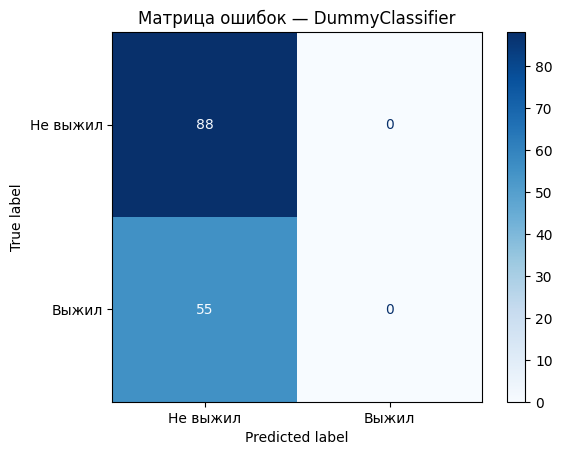

In [21]:
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_fit_processed, y_fit)

y_pred_baseline = baseline.predict(X_val_processed)

print("Accuracy:", round(accuracy_score(y_val, y_pred_baseline), 3))
print("Precision:", round(precision_score(y_val, y_pred_baseline, zero_division=0), 3))
print("Recall:", round(recall_score(y_val, y_pred_baseline, zero_division=0), 3))
print("F1:", round(f1_score(y_val, y_pred_baseline, zero_division=0), 3))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_baseline,
    labels=[0, 1],
    display_labels=["Не выжил", "Выжил"],
    cmap="Blues"
)

plt.title("Матрица ошибок — DummyClassifier")
plt.show()


**Вывод:** DummyClassifier показал Accuracy = 0.615, однако Precision, Recall и F1 равны нулю. Модель всегда предсказывает наиболее частый класс (0), поэтому правильно определила 88 погибших, но не распознала ни одного из 55 выживших.

Таким образом, Accuracy недостаточно для оценки качества классификации. Далее будем сравнивать модели преимущественно по F1-score.



## 6. Decision Tree

Обучим дерево решений и сравним качество на обучающей и валидационной выборках. Проверим, не возникает ли переобучения.


F1 на Fit: 0.974
F1 на Validation: 0.719

Метрики на Validation:
Accuracy: 0.776
Precision: 0.695
Recall: 0.745
F1: 0.719


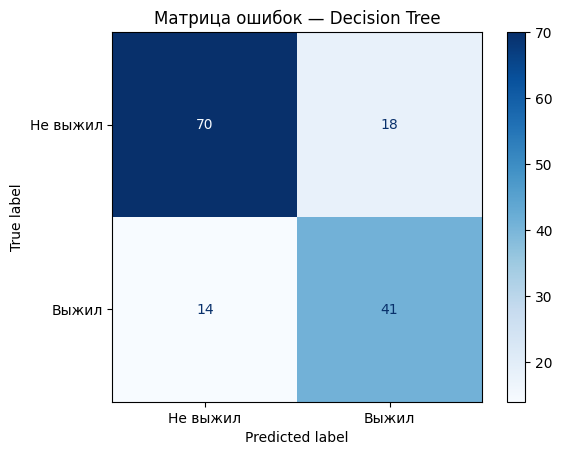

In [22]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=42)

tree.fit(X_fit_processed, y_fit)

y_pred_fit = tree.predict(X_fit_processed)
y_pred_val = tree.predict(X_val_processed)

print("F1 на Fit:", round(f1_score(y_fit, y_pred_fit), 3))
print("F1 на Validation:", round(f1_score(y_val, y_pred_val), 3))

print("\nМетрики на Validation:")
print("Accuracy:", round(accuracy_score(y_val, y_pred_val), 3))
print("Precision:", round(precision_score(y_val, y_pred_val), 3))
print("Recall:", round(recall_score(y_val, y_pred_val), 3))
print("F1:", round(f1_score(y_val, y_pred_val), 3))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_val,
    labels=[0, 1],
    display_labels=["Не выжил", "Выжил"],
    cmap="Blues"
)

plt.title("Матрица ошибок — Decision Tree")
plt.show()


### Влияние глубины дерева

Проверим, как максимальная глубина дерева влияет на качество классификации. Сравним F1-score на обучающей и валидационной выборках, чтобы найти баланс между недообучением и переобучением.


,max_depth,F1 Fit,F1 Validation
0,1,0.719,0.698
1,2,0.744,0.739
2,3,0.739,0.771
3,4,0.752,0.763
4,5,0.805,0.774
5,6,0.823,0.755
6,7,0.863,0.745
7,8,0.892,0.759
8,9,0.920,0.750
9,10,0.937,0.739


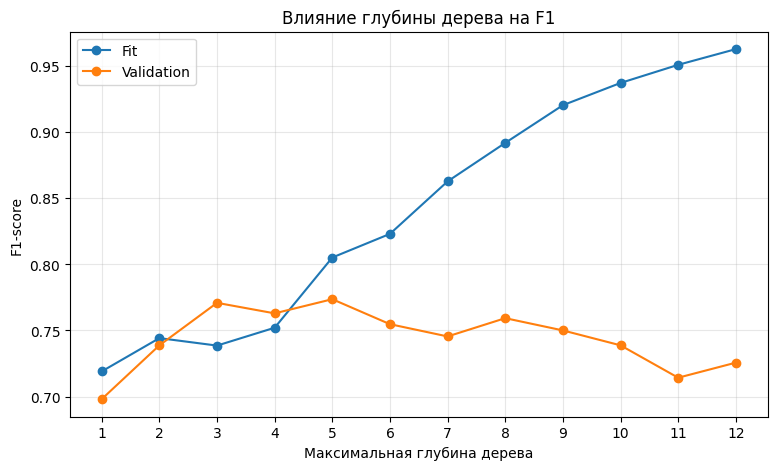

In [23]:
depths = range(1, 13)

fit_scores = []
val_scores = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_fit_processed, y_fit)

    fit_scores.append(
        f1_score(y_fit, model.predict(X_fit_processed))
    )

    val_scores.append(
        f1_score(y_val, model.predict(X_val_processed))
    )

results = pd.DataFrame({
    "max_depth": depths,
    "F1 Fit": fit_scores,
    "F1 Validation": val_scores
})

display(results.round(3))

plt.figure(figsize=(9, 5))
plt.plot(depths, fit_scores, marker="o", label="Fit")
plt.plot(depths, val_scores, marker="o", label="Validation")

plt.xlabel("Максимальная глубина дерева")
plt.ylabel("F1-score")
plt.title("Влияние глубины дерева на F1")
plt.xticks(list(depths))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Вывод:** наилучший F1 на валидационной выборке (0.774) получен при max_depth = 5. При дальнейшем увеличении глубины качество на обучающей выборке продолжает расти, однако на валидационной снижается, что указывает на переобучение.

Для дальнейшего сравнения моделей выберем дерево с max_depth = 5.


Accuracy: 0.832
Precision: 0.804
Recall: 0.745
F1: 0.774


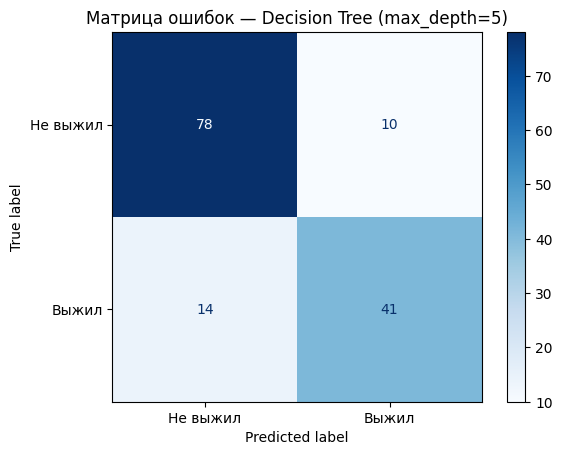

In [24]:
best_tree = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

best_tree.fit(X_fit_processed, y_fit)

y_pred_tree = best_tree.predict(X_val_processed)

print("Accuracy:", round(accuracy_score(y_val, y_pred_tree), 3))
print("Precision:", round(precision_score(y_val, y_pred_tree), 3))
print("Recall:", round(recall_score(y_val, y_pred_tree), 3))
print("F1:", round(f1_score(y_val, y_pred_tree), 3))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_tree,
    labels=[0, 1],
    display_labels=["Не выжил", "Выжил"],
    cmap="Blues"
)

plt.title("Матрица ошибок — Decision Tree (max_depth=5)")
plt.show()


### Визуализация дерева решений

Рассмотрим первые уровни обученного дерева, чтобы понять, какие признаки модель использует при классификации пассажиров.


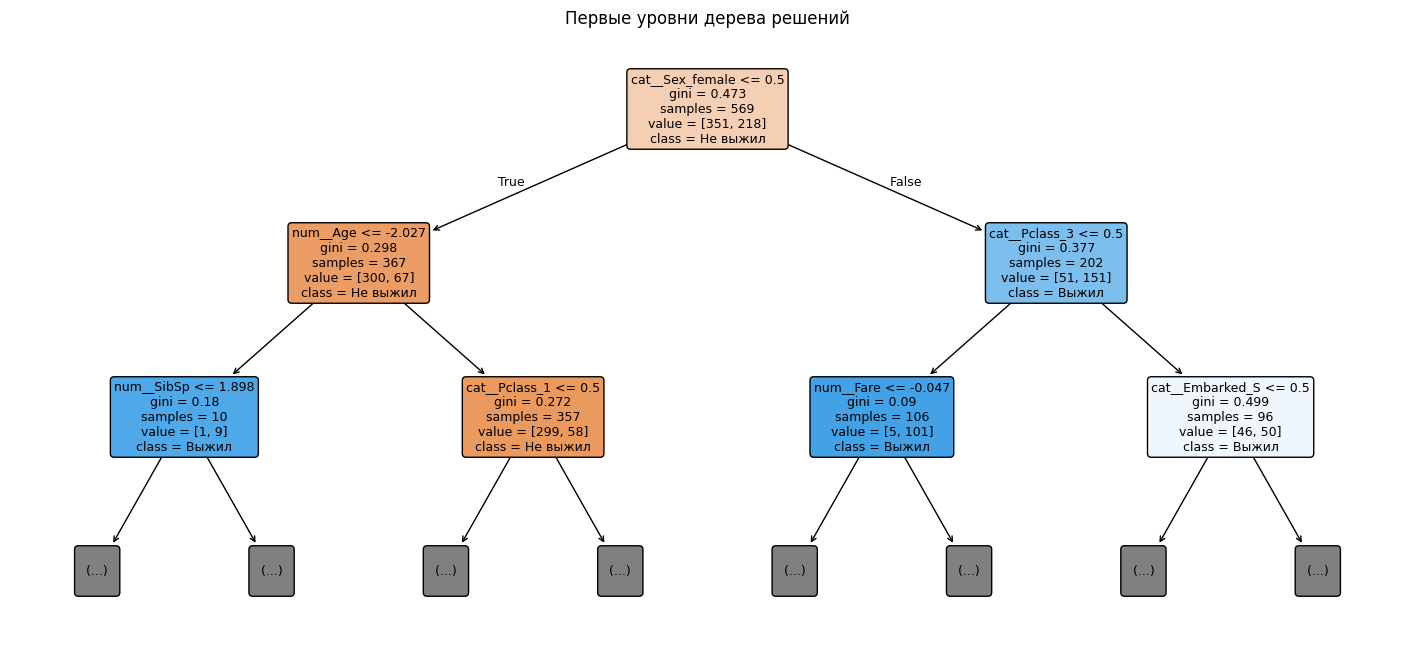

In [25]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 8))

plot_tree(
    best_tree,
    feature_names=preprocessor.get_feature_names_out(),
    class_names=["Не выжил", "Выжил"],
    max_depth=2,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Первые уровни дерева решений")
plt.show()


**Вывод:** ограничение глубины дерева до 5 улучшило F1 на Validation с 0.719 до 0.774. Количество ложноположительных предсказаний сократилось с 18 до 10, а число ложноотрицательных осталось равным 14.

Таким образом, Precision вырос с 0.695 до 0.804 при неизменном Recall = 0.745.



### Важность признаков

Оценим, какие признаки сильнее всего влияют на разделения в обученном дереве решений.



,Признак,Важность
7,cat__Sex_female,0.543
0,num__Age,0.133
6,cat__Pclass_3,0.123
3,num__Fare,0.087
4,cat__Pclass_1,0.064
11,cat__Embarked_S,0.038
1,num__SibSp,0.012
2,num__Parch,0.000
5,cat__Pclass_2,0.000
8,cat__Sex_male,0.000


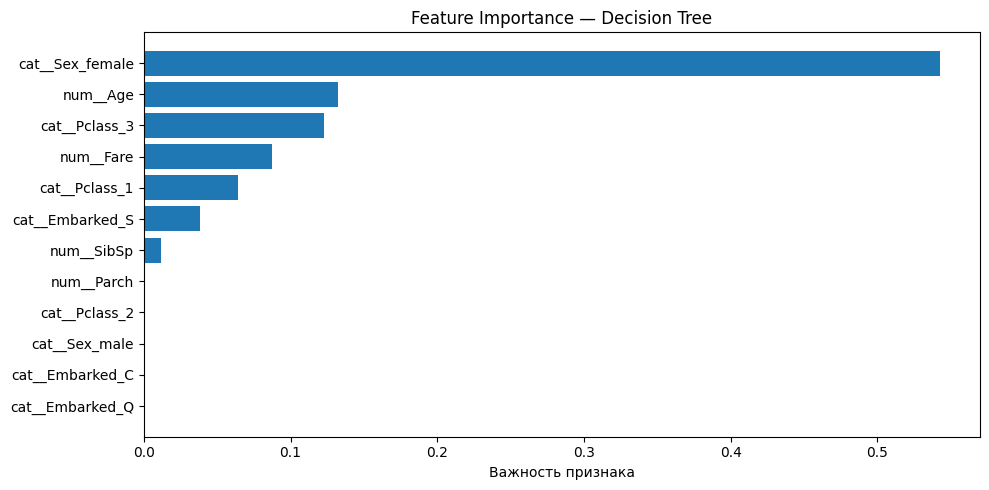

In [26]:
importance = pd.DataFrame({
    "Признак": preprocessor.get_feature_names_out(),
    "Важность": best_tree.feature_importances_
}).sort_values("Важность", ascending=False)

display(importance.round(3))

plt.figure(figsize=(10, 5))

plt.barh(
    importance["Признак"][::-1],
    importance["Важность"][::-1]
)

plt.xlabel("Важность признака")
plt.title("Feature Importance — Decision Tree")
plt.tight_layout()
plt.show()


**Вывод:** наиболее важным признаком для дерева оказался Sex_female (0.543). Далее следуют Age (0.133), Pclass_3 (0.123) и Fare (0.087).

Таким образом, в обученном дереве наибольшую роль играют пол пассажира, возраст и характеристики билета. Нулевая важность отдельных признаков не обязательно означает отсутствие полезной информации.



## 7. Random Forest

Обучим случайный лес из 200 деревьев и сравним его качество с Decision Tree. Оценим метрики на Validation и проверим наличие переобучения.


F1 на Fit: 0.975
F1 на Validation: 0.781

Метрики на Validation:
Accuracy: 0.839
Precision: 0.82
Recall: 0.745
F1: 0.781


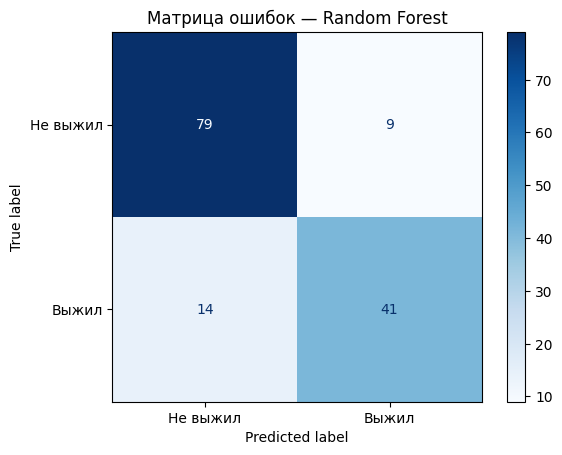

In [27]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

forest.fit(X_fit_processed, y_fit)

y_pred_forest_fit = forest.predict(X_fit_processed)
y_pred_forest_val = forest.predict(X_val_processed)

print("F1 на Fit:", round(f1_score(y_fit, y_pred_forest_fit), 3))
print("F1 на Validation:", round(f1_score(y_val, y_pred_forest_val), 3))

print("\nМетрики на Validation:")
print("Accuracy:", round(accuracy_score(y_val, y_pred_forest_val), 3))
print("Precision:", round(precision_score(y_val, y_pred_forest_val), 3))
print("Recall:", round(recall_score(y_val, y_pred_forest_val), 3))
print("F1:", round(f1_score(y_val, y_pred_forest_val), 3))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_forest_val,
    labels=[0, 1],
    display_labels=["Не выжил", "Выжил"],
    cmap="Blues"
)

plt.title("Матрица ошибок — Random Forest")
plt.show()


### Влияние глубины случайного леса

Проверим, как ограничение глубины деревьев влияет на F1-score случайного леса. Сравним результаты на Fit и Validation.


,Глубина,F1 Fit,F1 Validation
0,3,0.749,0.738
1,5,0.794,0.740
2,7,0.872,0.745
3,9,0.910,0.757
4,12,0.950,0.788
5,None,0.975,0.781


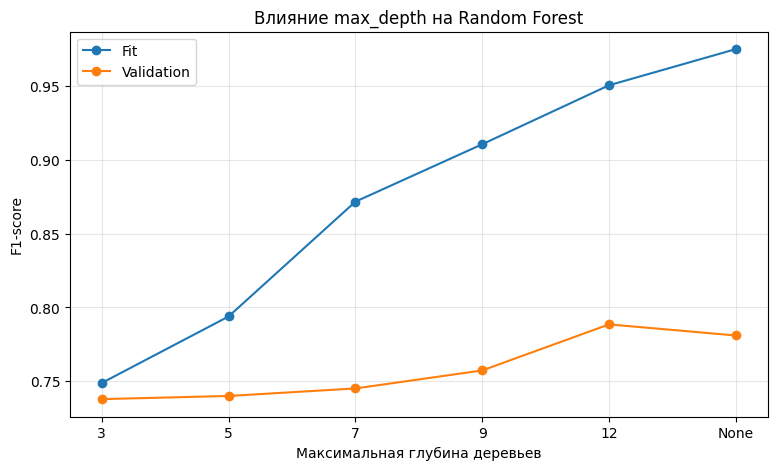

In [28]:
depth_options = [3, 5, 7, 9, 12, None]

forest_results = []

for depth in depth_options:
    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=depth,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_fit_processed, y_fit)

    forest_results.append({
        "Глубина": str(depth),
        "F1 Fit": f1_score(y_fit, model.predict(X_fit_processed)),
        "F1 Validation": f1_score(y_val, model.predict(X_val_processed))
    })

forest_depth_results = pd.DataFrame(forest_results)

display(forest_depth_results.round(3))

plt.figure(figsize=(9, 5))

plt.plot(
    forest_depth_results["Глубина"],
    forest_depth_results["F1 Fit"],
    marker="o",
    label="Fit"
)

plt.plot(
    forest_depth_results["Глубина"],
    forest_depth_results["F1 Validation"],
    marker="o",
    label="Validation"
)

plt.xlabel("Максимальная глубина деревьев")
plt.ylabel("F1-score")
plt.title("Влияние max_depth на Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Результаты Random Forest

| Параметр | Без ограничения | max_depth = 12 |
|---|---:|---:|
| Количество деревьев | 200 | 200 |
| F1 Fit | 0.975 | 0.950 |
| F1 Validation | 0.781 | 0.788 |
| Разница Fit и Validation | 0.194 | 0.162 |

**Вывод:** лучший результат среди проверенных вариантов получен при max_depth = 12. F1 на Validation вырос с 0.781 до 0.788, а разница между Fit и Validation уменьшилась с 0.194 до 0.162. Переобучение стало менее выраженным, но полностью не исчезло.



### Матрица ошибок выбранной модели

Рассмотрим метрики и матрицу ошибок Random Forest с max_depth = 12.


Accuracy: 0.846
Precision: 0.837
Recall: 0.745
F1: 0.788


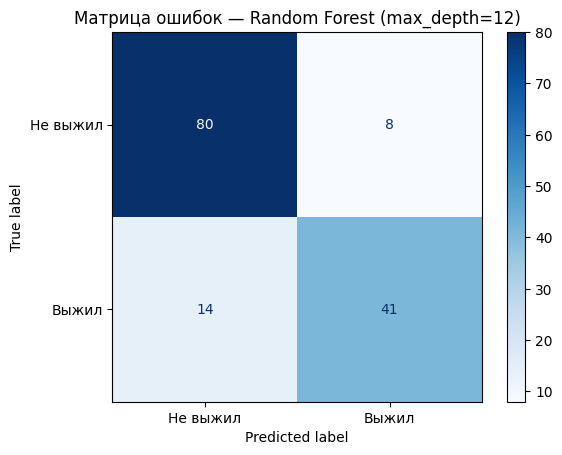

In [29]:
best_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

best_forest.fit(X_fit_processed, y_fit)

y_pred_best_forest = best_forest.predict(X_val_processed)

print("Accuracy:", round(accuracy_score(y_val, y_pred_best_forest), 3))
print("Precision:", round(precision_score(y_val, y_pred_best_forest), 3))
print("Recall:", round(recall_score(y_val, y_pred_best_forest), 3))
print("F1:", round(f1_score(y_val, y_pred_best_forest), 3))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_best_forest,
    labels=[0, 1],
    display_labels=["Не выжил", "Выжил"],
    cmap="Blues"
)

plt.title("Матрица ошибок — Random Forest (max_depth=12)")
plt.show()


### Важность признаков Random Forest

Оценим важность признаков в случайном лесу и сравним её с результатами одиночного дерева решений.


,Признак,Важность
3,num__Fare,0.234
0,num__Age,0.221
8,cat__Sex_male,0.167
7,cat__Sex_female,0.145
6,cat__Pclass_3,0.049
1,num__SibSp,0.045
2,num__Parch,0.041
4,cat__Pclass_1,0.039
5,cat__Pclass_2,0.020
11,cat__Embarked_S,0.018


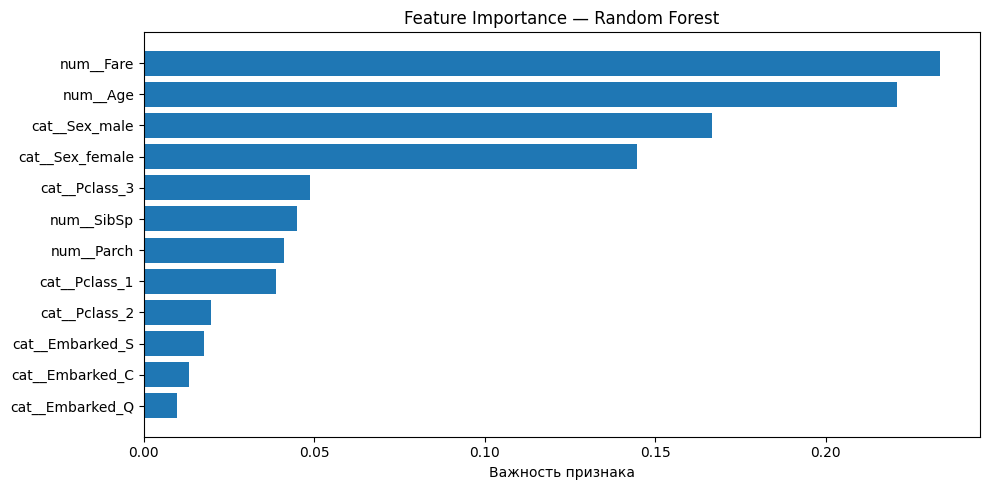

In [32]:
forest_importance = pd.DataFrame({
    "Признак": preprocessor.get_feature_names_out(),
    "Важность": best_forest.feature_importances_
}).sort_values("Важность", ascending=False)

display(forest_importance.round(3))

plt.figure(figsize=(10, 5))

plt.barh(
    forest_importance["Признак"][::-1],
    forest_importance["Важность"][::-1]
)

plt.xlabel("Важность признака")
plt.title("Feature Importance — Random Forest")
plt.tight_layout()
plt.show()


**Вывод:** в Random Forest наибольшую индивидуальную важность получили Fare (0.234) и Age (0.221). Суммарная важность признаков пола составила 0.312.

По сравнению с одиночным деревом важность распределилась между большим количеством признаков. Это связано с использованием разных разделений в ансамбле деревьев.



## 8. Gradient Boosting

Обучим градиентный бустинг и сравним его качество с Decision Tree и Random Forest. Проверим метрики на Fit и Validation, а также построим матрицу ошибок.


F1 на Fit: 0.877
F1 на Validation: 0.774

Метрики на Validation:
Accuracy: 0.832
Precision: 0.804
Recall: 0.745
F1: 0.774


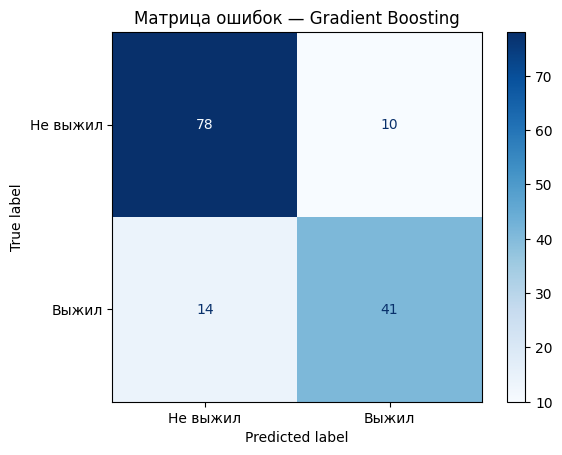

In [33]:
from sklearn.ensemble import GradientBoostingClassifier

boosting = GradientBoostingClassifier(
    random_state=42
)

boosting.fit(X_fit_processed, y_fit)

y_pred_boosting_fit = boosting.predict(X_fit_processed)
y_pred_boosting_val = boosting.predict(X_val_processed)

print("F1 на Fit:", round(f1_score(y_fit, y_pred_boosting_fit), 3))
print("F1 на Validation:", round(f1_score(y_val, y_pred_boosting_val), 3))

print("\nМетрики на Validation:")
print("Accuracy:", round(accuracy_score(y_val, y_pred_boosting_val), 3))
print("Precision:", round(precision_score(y_val, y_pred_boosting_val), 3))
print("Recall:", round(recall_score(y_val, y_pred_boosting_val), 3))
print("F1:", round(f1_score(y_val, y_pred_boosting_val), 3))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_boosting_val,
    labels=[0, 1],
    display_labels=["Не выжил", "Выжил"],
    cmap="Blues"
)

plt.title("Матрица ошибок — Gradient Boosting")
plt.show()


### Подбор параметров Gradient Boosting

Исследуем влияние количества деревьев и learning_rate на качество модели. Сравним F1-score на Fit и Validation для разных комбинаций параметров.


,learning_rate,n_estimators,F1 Fit,F1 Validation
7,0.20,100,0.904,0.796
5,0.10,200,0.906,0.785
6,0.20,50,0.866,0.781
4,0.10,100,0.877,0.774
2,0.05,200,0.875,0.774
3,0.10,50,0.842,0.769
8,0.20,200,0.955,0.764
0,0.05,50,0.782,0.747
1,0.05,100,0.833,0.733


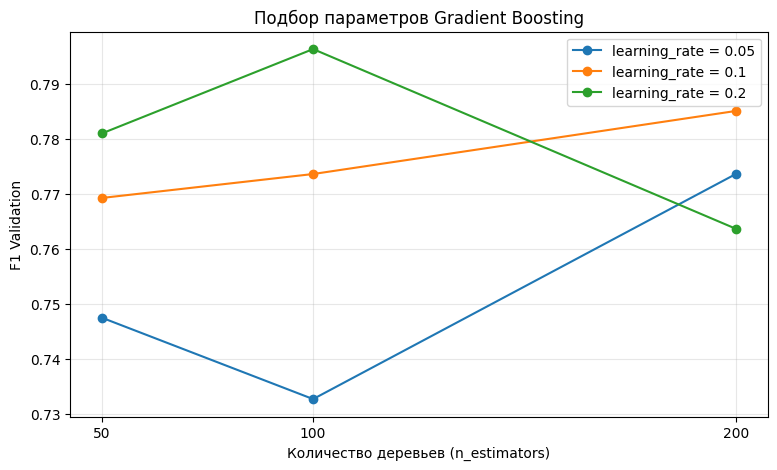

In [34]:
learning_rates = [0.05, 0.1, 0.2]
n_estimators_options = [50, 100, 200]

boosting_results = []

for rate in learning_rates:
    for n in n_estimators_options:
        model = GradientBoostingClassifier(
            n_estimators=n,
            learning_rate=rate,
            random_state=42
        )

        model.fit(X_fit_processed, y_fit)

        boosting_results.append({
            "learning_rate": rate,
            "n_estimators": n,
            "F1 Fit": f1_score(y_fit, model.predict(X_fit_processed)),
            "F1 Validation": f1_score(y_val, model.predict(X_val_processed))
        })

boosting_results = pd.DataFrame(boosting_results)

display(
    boosting_results.sort_values(
        "F1 Validation", ascending=False
    ).round(3)
)

plt.figure(figsize=(9, 5))

for rate in learning_rates:
    subset = boosting_results[
        boosting_results["learning_rate"] == rate
    ]

    plt.plot(
        subset["n_estimators"],
        subset["F1 Validation"],
        marker="o",
        label=f"learning_rate = {rate}"
    )

plt.xlabel("Количество деревьев (n_estimators)")
plt.ylabel("F1 Validation")
plt.title("Подбор параметров Gradient Boosting")
plt.xticks(n_estimators_options)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Лучшая модель Gradient Boosting

Наилучший F1 на Validation (0.796) получен при learning_rate = 0.2 и n_estimators = 100. Рассмотрим метрики и матрицу ошибок выбранной модели.


Accuracy: 0.846
Precision: 0.811
Recall: 0.782
F1: 0.796


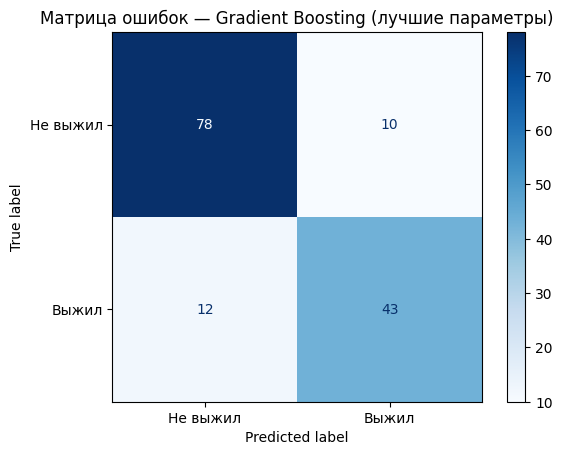

In [35]:
best_boosting = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.2,
    random_state=42
)

best_boosting.fit(X_fit_processed, y_fit)

y_pred_best_boosting = best_boosting.predict(X_val_processed)

print("Accuracy:", round(accuracy_score(y_val, y_pred_best_boosting), 3))
print("Precision:", round(precision_score(y_val, y_pred_best_boosting), 3))
print("Recall:", round(recall_score(y_val, y_pred_best_boosting), 3))
print("F1:", round(f1_score(y_val, y_pred_best_boosting), 3))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_best_boosting,
    labels=[0, 1],
    display_labels=["Не выжил", "Выжил"],
    cmap="Blues"
)

plt.title("Матрица ошибок — Gradient Boosting (лучшие параметры)")
plt.show()


### Результаты Gradient Boosting

| Параметр | Стандартная модель | После подбора |
|---|---:|---:|
| learning_rate | 0.1 | 0.2 |
| n_estimators | 100 | 100 |
| F1 Fit | 0.877 | 0.904 |
| F1 Validation | 0.774 | 0.796 |

**Вывод:** подбор параметров повысил F1 на Validation с 0.774 до 0.796. Настроенный Gradient Boosting немного превзошёл Random Forest (0.788), обнаружив 43 выживших вместо 41, но допустив больше ложноположительных ошибок.



## 9. Support Vector Machine (SVM)

Обучим SVM с RBF-ядром на масштабированных признаках. Сравним F1 на Fit и Validation, оценим основные метрики и построим матрицу ошибок.


F1 на Fit: 0.776
F1 на Validation: 0.788

Метрики на Validation:
Accuracy: 0.846
Precision: 0.837
Recall: 0.745
F1: 0.788


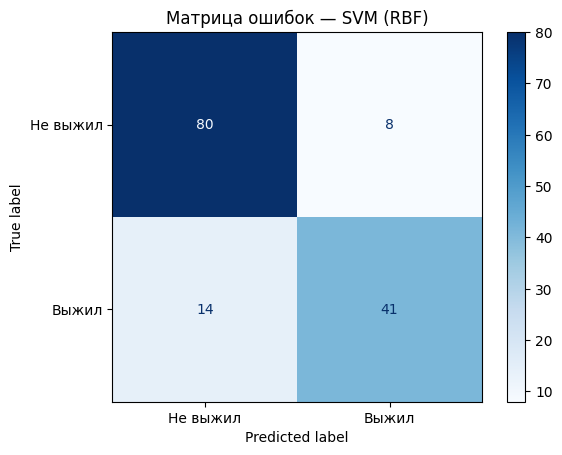

In [36]:
from sklearn.svm import SVC

svm = SVC(
    kernel="rbf",
    random_state=42
)

svm.fit(X_fit_processed, y_fit)

y_pred_svm_fit = svm.predict(X_fit_processed)
y_pred_svm_val = svm.predict(X_val_processed)

print("F1 на Fit:", round(f1_score(y_fit, y_pred_svm_fit), 3))
print("F1 на Validation:", round(f1_score(y_val, y_pred_svm_val), 3))

print("\nМетрики на Validation:")
print("Accuracy:", round(accuracy_score(y_val, y_pred_svm_val), 3))
print("Precision:", round(precision_score(y_val, y_pred_svm_val), 3))
print("Recall:", round(recall_score(y_val, y_pred_svm_val), 3))
print("F1:", round(f1_score(y_val, y_pred_svm_val), 3))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_svm_val,
    labels=[0, 1],
    display_labels=["Не выжил", "Выжил"],
    cmap="Blues"
)

plt.title("Матрица ошибок — SVM (RBF)")
plt.show()


### Подбор параметров SVM

Проверим влияние параметров C и gamma на F1-score. Сравним несколько комбинаций на Fit и Validation.


In [37]:
C_values = [0.1, 1, 10]
gamma_values = ["scale", 0.1, 1]

svm_results = []

for C in C_values:
    for gamma in gamma_values:
        model = SVC(
            kernel="rbf",
            C=C,
            gamma=gamma
        )

        model.fit(X_fit_processed, y_fit)

        svm_results.append({
            "C": C,
            "gamma": gamma,
            "F1 Fit": f1_score(y_fit, model.predict(X_fit_processed)),
            "F1 Validation": f1_score(y_val, model.predict(X_val_processed))
        })

svm_results = pd.DataFrame(svm_results)

display(
    svm_results.sort_values(
        "F1 Validation",
        ascending=False
    ).round(3)
)

,C,gamma,F1 Fit,F1 Validation
3,1.0,scale,0.776,0.788
6,10.0,scale,0.799,0.780
4,1.0,0.1,0.763,0.769
7,10.0,0.1,0.777,0.768
5,1.0,1,0.832,0.757
8,10.0,1,0.860,0.750
0,0.1,scale,0.750,0.686
1,0.1,0.1,0.744,0.680
2,0.1,1,0.467,0.474


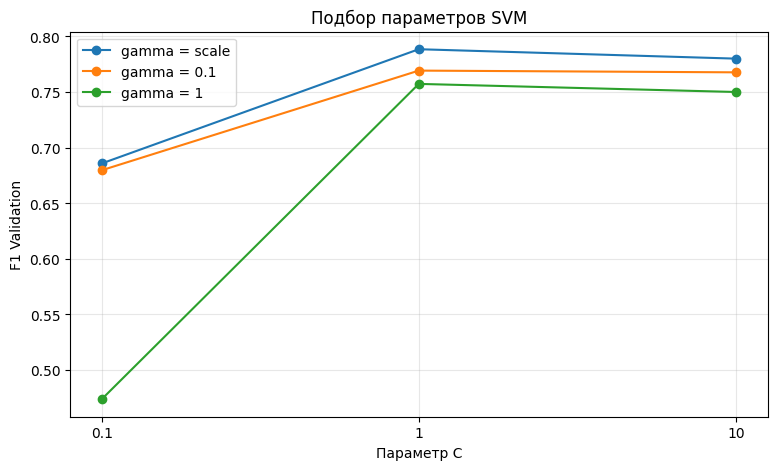

In [38]:
plt.figure(figsize=(9, 5))

for gamma in gamma_values:
    subset = svm_results[svm_results["gamma"] == gamma]

    plt.plot(
        range(len(C_values)),
        subset["F1 Validation"],
        marker="o",
        label=f"gamma = {gamma}"
    )

plt.xticks(range(len(C_values)), C_values)
plt.xlabel("Параметр C")
plt.ylabel("F1 Validation")
plt.title("Подбор параметров SVM")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Результаты SVM

| Параметр | Лучшее значение |
|---|---|
| Ядро | RBF |
| C | 1 |
| gamma | scale |
| F1 Fit | 0.776 |
| F1 Validation | 0.788 |

**Вывод:** лучшими оказались стандартные параметры SVM. Увеличение C и gamma в некоторых комбинациях приводило к переобучению, а слишком маленькое C — к недообучению. SVM показал тот же F1, что и Random Forest (0.788).



## 10. K-Nearest Neighbors (KNN)

Обучим KNN с пятью ближайшими соседями на масштабированных признаках. Сравним F1 на Fit и Validation, а также проанализируем матрицу ошибок.


F1 на Fit: 0.782
F1 на Validation: 0.743

Метрики на Validation:
Accuracy: 0.811
Precision: 0.78
Recall: 0.709
F1: 0.743


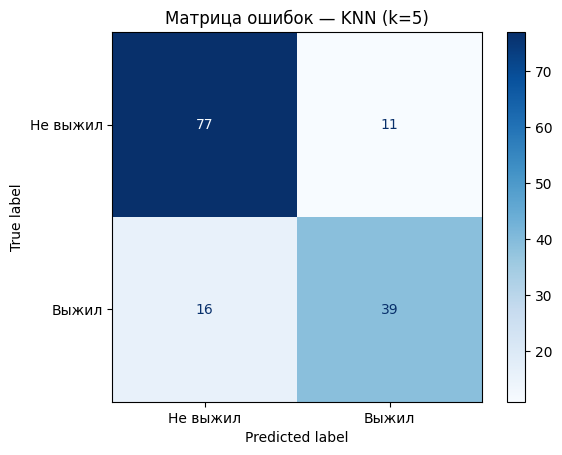

In [39]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_fit_processed, y_fit)

y_pred_knn_fit = knn.predict(X_fit_processed)
y_pred_knn_val = knn.predict(X_val_processed)

print("F1 на Fit:", round(f1_score(y_fit, y_pred_knn_fit), 3))
print("F1 на Validation:", round(f1_score(y_val, y_pred_knn_val), 3))

print("\nМетрики на Validation:")
print("Accuracy:", round(accuracy_score(y_val, y_pred_knn_val), 3))
print("Precision:", round(precision_score(y_val, y_pred_knn_val), 3))
print("Recall:", round(recall_score(y_val, y_pred_knn_val), 3))
print("F1:", round(f1_score(y_val, y_pred_knn_val), 3))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_knn_val,
    labels=[0, 1],
    display_labels=["Не выжил", "Выжил"],
    cmap="Blues"
)

plt.title("Матрица ошибок — KNN (k=5)")
plt.show()


### Подбор количества соседей

Исследуем влияние параметра n_neighbors на качество KNN. Сравним F1-score на Fit и Validation для разных значений k.


,k,F1 Fit,F1 Validation
0,1,0.975,0.719
1,3,0.817,0.748
2,5,0.782,0.743
3,7,0.768,0.729
4,9,0.772,0.736
5,11,0.770,0.771
6,15,0.768,0.706
7,21,0.757,0.745
8,31,0.749,0.673


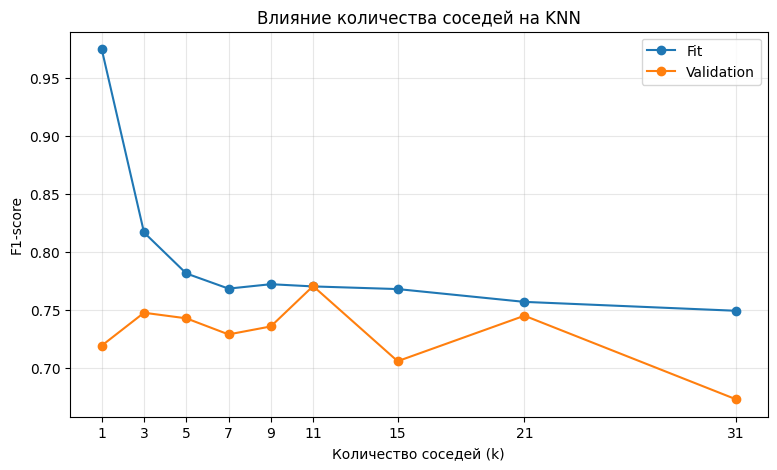

In [40]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31]

knn_results = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_fit_processed, y_fit)

    knn_results.append({
        "k": k,
        "F1 Fit": f1_score(y_fit, model.predict(X_fit_processed)),
        "F1 Validation": f1_score(y_val, model.predict(X_val_processed))
    })

knn_results = pd.DataFrame(knn_results)

display(knn_results.round(3))

plt.figure(figsize=(9, 5))

plt.plot(
    knn_results["k"],
    knn_results["F1 Fit"],
    marker="o",
    label="Fit"
)

plt.plot(
    knn_results["k"],
    knn_results["F1 Validation"],
    marker="o",
    label="Validation"
)

plt.xlabel("Количество соседей (k)")
plt.ylabel("F1-score")
plt.title("Влияние количества соседей на KNN")
plt.xticks(k_values)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Лучшая модель KNN

Наилучший F1 на Validation (0.771) получен при k = 11. Рассмотрим метрики и матрицу ошибок выбранной модели.


Accuracy: 0.825
Precision: 0.778
Recall: 0.764
F1: 0.771


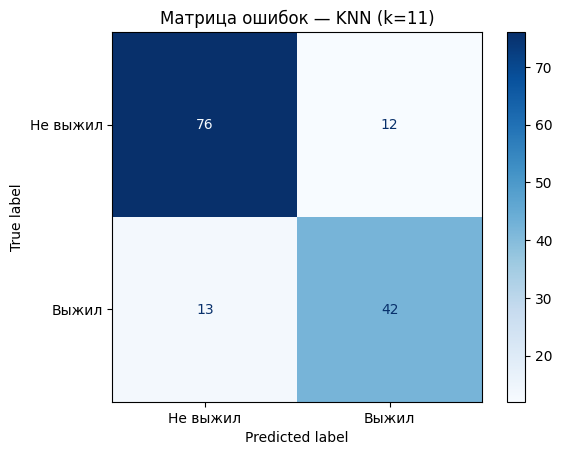

In [41]:
best_knn = KNeighborsClassifier(n_neighbors=11)

best_knn.fit(X_fit_processed, y_fit)

y_pred_best_knn = best_knn.predict(X_val_processed)

print("Accuracy:", round(accuracy_score(y_val, y_pred_best_knn), 3))
print("Precision:", round(precision_score(y_val, y_pred_best_knn), 3))
print("Recall:", round(recall_score(y_val, y_pred_best_knn), 3))
print("F1:", round(f1_score(y_val, y_pred_best_knn), 3))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_best_knn,
    labels=[0, 1],
    display_labels=["Не выжил", "Выжил"],
    cmap="Blues"
)

plt.title("Матрица ошибок — KNN (k=11)")
plt.show()


### Результаты KNN

| Параметр | До подбора | После подбора |
|---|---:|---:|
| n_neighbors | 5 | 11 |
| F1 Fit | 0.782 | 0.770 |
| F1 Validation | 0.743 | 0.771 |
| Precision | 0.780 | 0.778 |
| Recall | 0.709 | 0.764 |

**Вывод:** лучший F1 на Validation (0.771) получен при k = 11. Увеличение количества соседей с 5 до 11 помогло обнаружить больше выживших и улучшило итоговое качество классификации.



## 11. Сравнение моделей

Сравним все обученные алгоритмы на одной валидационной выборке. Основной критерий выбора — F1-score для класса Survived = 1. Дополнительно рассмотрим Accuracy, Precision, Recall и количество ошибок.


In [42]:
from sklearn.metrics import confusion_matrix

predictions = {
    "DummyClassifier": y_pred_baseline,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_best_forest,
    "Gradient Boosting": y_pred_best_boosting,
    "SVM": y_pred_svm_val,
    "KNN": y_pred_best_knn
}

comparison_rows = []

for name, y_pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred, labels=[0, 1]
    ).ravel()

    comparison_rows.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1": f1_score(y_val, y_pred, zero_division=0),
        "FP": fp,
        "FN": fn
    })

comparison = pd.DataFrame(comparison_rows)
comparison = comparison.sort_values("F1", ascending=False)

display(comparison.round(3))

,Модель,Accuracy,Precision,Recall,F1,FP,FN
3,Gradient Boosting,0.846,0.811,0.782,0.796,10,12
2,Random Forest,0.846,0.837,0.745,0.788,8,14
4,SVM,0.846,0.837,0.745,0.788,8,14
1,Decision Tree,0.832,0.804,0.745,0.774,10,14
5,KNN,0.825,0.778,0.764,0.771,12,13
0,DummyClassifier,0.615,0.000,0.000,0.000,0,55


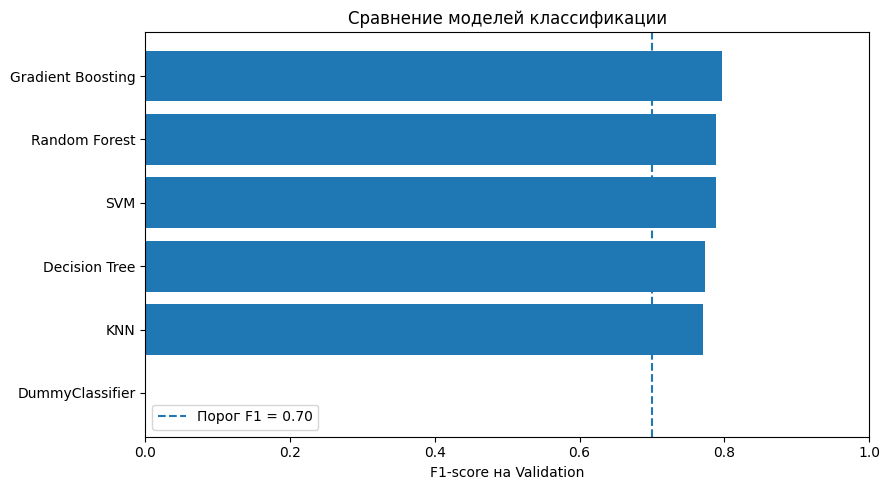

In [43]:
plt.figure(figsize=(9, 5))

plt.barh(
    comparison["Модель"][::-1],
    comparison["F1"][::-1]
)

plt.axvline(
    0.70,
    linestyle="--",
    label="Порог F1 = 0.70"
)

plt.xlabel("F1-score на Validation")
plt.title("Сравнение моделей классификации")
plt.xlim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()


## 12. Анализ ошибок по группам пассажиров

Проверим, как Gradient Boosting классифицирует пассажиров разного пола и класса билета. Сравним количество ложноположительных и ложноотрицательных ошибок, Accuracy и Recall.


In [46]:
import numpy as np

# Данные Validation и предсказания лучшей модели
errors = val_df[["Survived", "Sex", "Pclass", "Age"]].copy()
errors["Predicted"] = y_pred_best_boosting

# Отдельно отмечаем два типа ошибок
errors["FP"] = (
    (errors["Survived"] == 0) &
    (errors["Predicted"] == 1)
).astype(int)

errors["FN"] = (
    (errors["Survived"] == 1) &
    (errors["Predicted"] == 0)
).astype(int)

# Функция для сравнения групп
def group_metrics(column):
    table = errors.groupby(column).agg(
        Всего=("Survived", "size"),
        Выжили=("Survived", "sum"),
        FP=("FP", "sum"),
        FN=("FN", "sum")
    )

    table["Accuracy"] = (
        (table["Всего"] - table["FP"] - table["FN"])
        / table["Всего"]
    )

    table["Recall"] = (
        (table["Выжили"] - table["FN"])
        / table["Выжили"].replace(0, np.nan)
    )

    return table.round(3)

print("Ошибки по полу:")
display(group_metrics("Sex"))

print("Ошибки по классу билета:")
display(group_metrics("Pclass"))

Ошибки по полу:


,Всего,Выжили,FP,FN,Accuracy,Recall
Sex,,,,,,
female,51,37,7,3,0.804,0.919
male,92,18,3,9,0.870,0.500


Ошибки по классу билета:


,Всего,Выжили,FP,FN,Accuracy,Recall
Pclass,,,,,,
1,34,20,3,1,0.882,0.950
2,30,17,1,2,0.900,0.882
3,79,18,6,9,0.810,0.500



### Ошибки по возрастным группам

Разделим пассажиров на возрастные группы и сравним качество классификации. Пассажиров с неизвестным возрастом рассмотрим отдельно.


In [47]:
# Создаём возрастные группы
errors["AgeGroup"] = pd.cut(
    errors["Age"],
    bins=[0, 18, 40, 60, float("inf")],
    labels=["До 18", "18–39", "40–59", "60+"],
    right=False
)

# Отдельная группа для неизвестного возраста
errors["AgeGroup"] = (
    errors["AgeGroup"]
    .cat.add_categories(["Неизвестен"])
    .fillna("Неизвестен")
)

# Используем нашу функцию из предыдущей ячейки
age_metrics = group_metrics("AgeGroup")

display(age_metrics)

,Всего,Выжили,FP,FN,Accuracy,Recall
AgeGroup,,,,,,
До 18,18,10,3,0,0.833,1.000
18–39,65,26,5,7,0.815,0.731
40–59,22,9,1,2,0.864,0.778
60+,4,0,0,0,1.000,NaN
Неизвестен,34,10,1,3,0.882,0.700


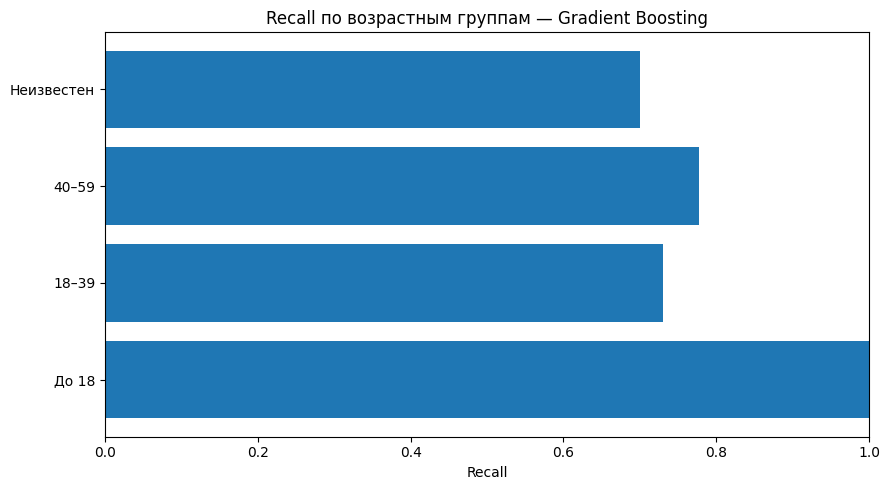

In [48]:
# Показываем только группы, где Recall определён
age_plot = age_metrics.dropna(subset=["Recall"])

plt.figure(figsize=(9, 5))

plt.barh(
    age_plot.index.astype(str),
    age_plot["Recall"]
)

plt.xlabel("Recall")
plt.title("Recall по возрастным группам — Gradient Boosting")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


### Итоги анализа ошибок

| Группа | Recall |
|---|---:|
| Женщины | 0.919 |
| Мужчины | 0.500 |
| 1-й класс | 0.950 |
| 2-й класс | 0.882 |
| 3-й класс | 0.500 |
| До 18 лет | 1.000 |
| Неизвестный возраст | 0.700 |

**Вывод:** Gradient Boosting лучше распознаёт выживших женщин и пассажиров первого класса. Наибольшие трудности возникают с выжившими мужчинами и пассажирами третьего класса — в обеих группах Recall составляет 0.500.

Среди детей до 18 лет найдены все 10 выживших. Для пассажиров старше 60 лет Recall не определён, так как в этой группе не было выживших. При интерпретации результатов необходимо учитывать небольшие размеры отдельных групп.



## 13. Финальная оценка модели

Выбрана модель Gradient Boosting с learning_rate = 0.2 и n_estimators = 100.

Заново обучим предобработку и модель на полном Train (712 пассажиров), после чего один раз оценим качество на отложенной Test-выборке.


Accuracy: 0.799
Precision: 0.8
Recall: 0.638
F1: 0.71


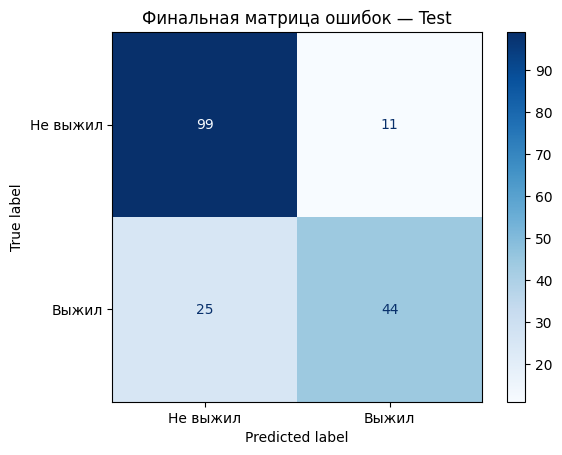

In [49]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline

final_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.2,
        random_state=42
    ))
])

X_train = train_df[features]
y_train = train_df["Survived"]

X_test = test_df[features]
y_test = test_df["Survived"]

# Обучаем всю последовательность только на Train
final_model.fit(X_train, y_train)

# Один раз проверяем на Test
y_pred_test = final_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred_test), 3))
print("Precision:", round(precision_score(y_test, y_pred_test), 3))
print("Recall:", round(recall_score(y_test, y_pred_test), 3))
print("F1:", round(f1_score(y_test, y_pred_test), 3))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_test,
    labels=[0, 1],
    display_labels=["Не выжил", "Выжил"],
    cmap="Blues"
)

plt.title("Финальная матрица ошибок — Test")
plt.show()


## 14. Итоговые выводы

В ходе лабораторной работы была решена задача бинарной классификации пассажиров Titanic по признаку `Survived`.

Были исследованы данные 891 пассажира, обработаны пропуски и категориальные признаки, выполнено разделение на обучающую и тестовую выборки. Для сравнения обучены DummyClassifier, Decision Tree, Random Forest, Gradient Boosting, SVM и KNN.

### Сравнение моделей

| Модель | F1 на Validation |
|---|---:|
| DummyClassifier | 0.000 |
| Decision Tree | 0.774 |
| Random Forest | 0.788 |
| Gradient Boosting | **0.796** |
| SVM | 0.788 |
| KNN | 0.771 |

Лучший результат на Validation показал Gradient Boosting с параметрами `learning_rate=0.2` и `n_estimators=100`. Эта модель была выбрана для финального тестирования.

### Финальная оценка

| Метрика | Test |
|---|---:|
| Accuracy | 0.799 |
| Precision | 0.800 |
| Recall | 0.638 |
| F1-score | **0.710** |
